# 11주차 학생용 워크북: 분류(Classification) - KNN과 의사결정나무 실습

* **이름:** 박하솜
* **학번:** 20244308
* **제출일:** 11.11

---

## 📌 주차 요약
- 회귀(수치 예측) vs 분류(카테고리 판별).
- KNN: 유유상종 원리 및 이웃 K 홀수 선택.
- 의사결정나무: 스무고개 원리, 지니 불순도, 가지치기(max_depth).
- 과적합(Overfitting) 예방 및 8:2 데이터 분리 뉘앙스 (테스트 세트 튜닝 엄금).
- (심화) K-겹 교차검증(Cross-Validation), 특성 중요도(feature_importances_).

---

## 1. 🔍 개념 확인 단답형 & 퀴즈

**[문항 1]** 수치를 예측하는 회귀(Regression)와 달리 몇 개의 카테고리/종류 중 하나를 판별하는 머신러닝 문제는?
* **정답:** 분류(Classification)
* **해설:** 사과/오렌지, 합격/불합격 등 범주를 판별합니다.

**[문항 2]** '유유상종' 원리를 바탕으로 가장 가까운 이웃들의 다수결로 종류를 정하는 알고리즘은?
* **정답:** KNN(K-Nearest Neighbors, K-최근접 이웃)
* **해설:** 가깝게 위치한 데이터점들의 종류를 봅니다.

**[문항 3]** KNN 알고리즘에서 이웃의 개수 K를 고를 때 동점 방지를 위해 주로 사용하는 숫자 형태는?
* **정답:** 홀수(예: 1, 3, 5). 두 범주에서 동점을 피하기 위해 사용한다.
* **해설:** 짝수일 경우 2대 2 동점이 발생할 수 있습니다.

**[문항 4]** 사람이 생각하는 스무고개 질문 방식처럼 데이터를 가장 덜 섞이게 나누는 대표적 분류 알고리즘은?
* **정답:** 의사결정나무(Decision Tree)
* **해설:** 직관적인 예/아니오 질문 가지치기 구조입니다.

**[문항 5]** 의사결정나무에서 데이터가 깨끗하게 분리되지 못하고 섞여 있는 무질서도를 나타내는 지표는?
* **정답:** 지니 불순도(Gini Impurity)
* **해설:** 0일 때 가장 순수한 상태입니다.

**[문항 6]** 의사결정나무가 과도하게 깊어져 훈련 데이터만 외우는 과적합을 방지하기 위해 질문 횟수를 제한하는 파라미터는?
* **정답:** max_depth
* **해설:** 트리의 최대 깊이를 제한하는 가지치기 파라미터입니다.

**[문항 7]** 모델이 훈련 데이터만 달달 외워 처음 만나는 실전 테스트 데이터를 망치는 현상을 무엇이라 하나요?
* **정답:** 과적합(Overfitting)
* **해설:** 기출문제 암기 부작용입니다.

**[문항 8]** 테스트 데이터(Test Set)를 사용할 때 절대 하지 말아야 하는 엄격한 금기 철칙은?
* **정답:** 테스트 점수를 보며 모델의 파라미터를 반복 조정(튜닝)하는 것. 테스트 세트는 최종 평가에만 사용한다.
* **해설:** 테스트 세트에 오염되어 데이터 누출이 발생합니다.

**[문항 9]** Scikit-learn에서 데이터를 훈련용과 테스트용으로 나누어주는 함수 명칭은?
* **정답:** train_test_split()
* **해설:** X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2) 형태로 씁니다.

**[문항 10]** 훈련 데이터 정확도는 100%인데 테스트 데이터 정확도가 50%로 급락할 때 의심되는 상태는?
* **정답:** 과적합(Overfitting)
* **해설:** 실전 응용 능력을 잃어버린 상태입니다.

**[문항 11]** (심화) `cross_val_score(model, X, y, cv=5)`처럼 데이터를 5조각으로 나눠 매번 다른 조각을 테스트로 삼아 5번 반복 평가하는 방법을 무엇이라 하나요?
* **정답:** 5-겹 교차검증(5-Fold Cross-Validation)
* **해설:** 한 번의 분리 결과에만 의존하지 않고 평균 점수로 신뢰도를 높입니다.

**[문항 12]** (심화) 의사결정나무가 분류를 수행할 때 각 입력 변수가 기여한 중요도를 수치로 알려주는 모델 속성은?
* **정답:** feature_importances_
* **해설:** 특성 중요도 계수를 반환합니다.

---

## 2. ✏️ 간단한 기초 코딩 연습

> **📌 [연습 1] train_test_split() 으로 훈련/테스트 데이터 8:2 분리하기**<br>
> **💡 힌트:**<br>
> 전체 데이터를 훈련용(80%)과 테스트용(20%)으로 나누어주는 Scikit-learn 함수는 무엇일까요?<br>
> **📋 예상 출력:**<br>
> `분리 완료`

In [1]:
from sklearn.model_selection import train_test_split
import pandas as pd
X = pd.DataFrame({'w': [200, 250, 150, 180], 's': [10, 12, 8, 9]})
y = ['사과', '사과', '오렌지', '오렌지']
# 테스트 비율 20%, 실행할 때마다 같은 데이터로 분리
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
print('분리 완료')

분리 완료


> **📌 [연습 2] KNeighborsClassifier(n_neighbors=3) 분류기 생성 및 학습**<br>
> **💡 힌트:**<br>
> 가장 가까운 이웃 K개의 다수결로 종류를 정하는 KNN 분류기 클래스를 떠올려 보세요.<br>
> **📋 예상 출력:**<br>
> `학습 완료`

In [2]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_tr, y_tr)  # 훈련 데이터로 학습
print('학습 완료')

학습 완료


> **📌 [연습 3] DecisionTreeClassifier(max_depth=3) 트리 모델 생성 및 학습**<br>
> **💡 힌트:**<br>
> 스무고개 질문 방식으로 데이터를 덜 섞이게 나누는 결정 트리 분류 클래스는 무엇일까요?<br>
> **📋 예상 출력:**<br>
> `학습 완료`

In [3]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_tr, y_tr)  # 훈련 데이터로 학습
print('학습 완료')

학습 완료


> **📌 [연습 4] plot_tree(filled=True) 로 의사결정나무 시각화하기**<br>
> **💡 힌트:**<br>
> 학습된 트리의 질문 규칙 구조를 다이어그램 이미지로 그려주는 시각화 함수는 무엇일까요?<br>
> **📋 예상 출력:**<br>
> `트리 다이어그램 시각화`

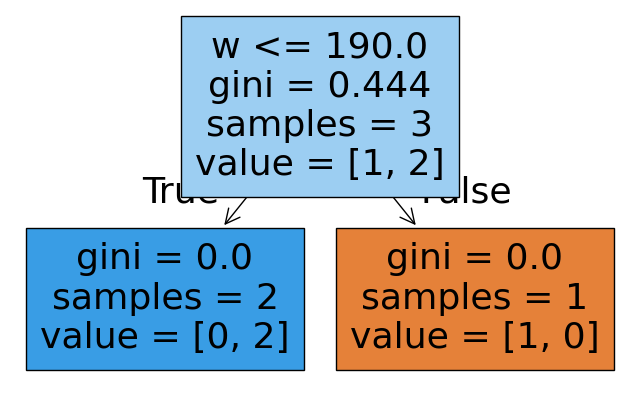

In [4]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(8, 5))
plot_tree(dt, filled=True, feature_names=X.columns)
plt.show()

> **📌 [연습 5] knn.score() / dt.feature_importances_ 로 결과 확인하기**<br>
> **💡 힌트:**<br>
> 테스트 데이터 분류 정확도(score)와 트리의 특성 중요도(feature_importances_)를 각각 출력해 보세요.<br>
> **📋 예상 출력:**<br>
> `KNN 테스트 정확도: 1.0` / `특성 중요도: [...]`

In [5]:
# 4개 중 1개가 테스트용이다. 훈련 3개의 다수결이므로 예시 1.0과 다를 수 있다.
print('KNN 테스트 정확도:', knn.score(X_te, y_te))
print('특성 중요도:', dt.feature_importances_.round(3))

KNN 테스트 정확도: 0.0
특성 중요도: [1. 0.]


---

## 3. 🚀 실전 코딩

### [문제 1] 과일 데이터 KNN(K=3) 분류기 구축 및 예측
* **📄 문제 설명:** 아래 과일 데이터 `df_fruit`를 바탕으로 `KNeighborsClassifier(n_neighbors=3)` 모델을 학습시키고, **(무게 240g, 당도 11)**인 새로운 과일의 종류를 예측하여 출력하세요.

In [6]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

df_fruit = pd.DataFrame({
    '무게': [220, 250, 230, 150, 170, 160],
    '당도': [12, 14, 11, 8, 9, 7],
    '종류': ['사과', '사과', '사과', '오렌지', '오렌지', '오렌지']
})

* **💡 AI 프롬프트 작성 힌트 (범위 초과 방지 가이드):**  
  AI에게 질문할 때 아래 3가지 요구사항을 프롬프트에 포함하여 질문을 조립해 보세요.  
  1. `X = df_fruit[['무게', '당도']]`, `y = df_fruit['종류']`로 특성과 라벨을 분리하기  
  2. `KNeighborsClassifier(n_neighbors=3)` 객체를 생성해 `fit(X, y)` 학습하기  
  3. `predict(pd.DataFrame({'무게': [240], '당도': [11]}))` 또는 `predict([[240, 11]])`로 새 과일 종류 출력하기  
  4. ⚠️ **[범위 초과 방지]** *"훈련/테스트 분리 없이 단일 KNN 모델 학습 및 예측 코드를 초보자용 주석과 함께 10줄 이내로 작성해 줘."*

In [7]:
# 입력 특성(무게, 당도)과 정답(종류)을 분리
X_fruit = df_fruit[['무게', '당도']]
y_fruit = df_fruit['종류']
# K=3인 KNN을 전체 과일 데이터로 학습
knn_fruit = KNeighborsClassifier(n_neighbors=3)
knn_fruit.fit(X_fruit, y_fruit)
# 학습 때와 같은 열 이름을 사용해 새 과일 예측
new_fruit = pd.DataFrame({'무게': [240], '당도': [11]})
print('예측 과일:', knn_fruit.predict(new_fruit)[0])

예측 과일: 사과


---

### [문제 2] 붓꽃 데이터 8:2 분리 후 KNN vs 의사결정나무 테스트 정확도 비교
* **📄 문제 설명:** `load_iris()` 데이터를 8:2로 분리한 뒤, **KNN(K=3)**과 **의사결정나무(`max_depth=3`)** 모델을 동일한 훈련 세트로 학습시키고, 두 모델의 테스트 정확도를 **비교 요약 데이터프레임(`df_compare`)**으로 출력하세요.

In [8]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

iris = load_iris()
X_tr, X_te, y_tr, y_te = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)

* **💡 AI 프롬프트 작성 힌트 (범위 초과 방지 가이드):**  
  AI에게 질문할 때 아래 3가지 요구사항을 프롬프트에 포함하여 질문을 조립해 보세요.  
  1. `knn = KNeighborsClassifier(n_neighbors=3).fit(X_tr, y_tr)`  
  2. `tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)`  
  3. `knn.score(X_te, y_te)`와 `tree.score(X_te, y_te)`를 구해 '모델'과 '테스트 정확도' 컬럼을 가진 판다스 데이터프레임 표로 출력하기  
  4. ⚠️ **[범위 초과 방지]** *"복잡한 교차검증 없이 단일 score() 결과만 깔끔한 DataFrame 표로 정리해 줘."*

In [9]:
# 두 모델을 동일한 훈련 세트로 학습
knn = KNeighborsClassifier(n_neighbors=3).fit(X_tr, y_tr)
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
# 테스트 세트는 평가에만 사용하고 점수에 맞춰 튜닝하지 않는다.
df_compare = pd.DataFrame({
    '모델': ['KNN(K=3)', '의사결정나무(max_depth=3)'],
    '테스트 정확도': [knn.score(X_te, y_te), tree.score(X_te, y_te)]
})
df_compare

,모델,테스트 정확도
0,KNN(K=3),1.0
1,의사결정나무(max_depth=3),1.0


---

### [문제 3] 5-Fold 교차검증으로 붓꽃 분류 모델 평균 정확도 산출
* **📄 문제 설명:** `cross_val_score()`를 사용하여 `load_iris()` 데이터 전체에 대해 KNN(K=3) 모델의 **5개 폴드(Fold)별 정확도**와 **최종 평균 정확도**를 소수점 셋째 자리까지 반올림하여 출력하세요.
* **💡 AI 프롬프트 작성 힌트 (범위 초과 방지 가이드):**  
  AI에게 질문할 때 아래 3가지 요구사항을 프롬프트에 포함하여 질문을 조립해 보세요.  
  1. `from sklearn.model_selection import cross_val_score` 임포트하기  
  2. `scores = cross_val_score(knn, iris.data, iris.target, cv=5)` 실행하기  
  3. 5개 점수 배열(`scores.round(3)`)과 평균 정확도(`scores.mean().round(3)`)를 출력하기  
  4. ⚠️ **[범위 초과 방지]** *"수동 반복문(for문) 대신 sklearn 내장 cross_val_score(..., cv=5) 함수 한 줄로 간결하게 작성해 줘."*

In [10]:
from sklearn.model_selection import cross_val_score
# 문제에서 지정한 전체 붓꽃 데이터로 5-겹 교차검증 수행
scores = cross_val_score(knn, iris.data, iris.target, cv=5)
print('5개 폴드별 정확도:', scores.round(3))
print('평균 정확도:', scores.mean().round(3))

5개 폴드별 정확도: [0.967 0.967 0.933 0.967 1.   ]
평균 정확도: 0.967


---

### [문제 4] 붓꽃 데이터 결정트리 시각화 및 특성 중요도 요약
* **📄 문제 설명:** 문제 2에서 학습된 의사결정나무 모델(`tree`)을 `plot_tree(filled=True)`로 시각화하고, 4개 특성(`iris.feature_names`)별 기여도를 담은 **특성 중요도 요약 데이터프레임(`df_importance`)**을 생성하여 출력하세요.
* **💡 AI 프롬프트 작성 힌트 (범위 초과 방지 가이드):**  
  AI에게 질문할 때 아래 3가지 요구사항을 프롬프트에 포함하여 질문을 조립해 보세요.  
  1. `plt.figure(figsize=(10, 6))` 및 `plot_tree(tree, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)`로 트리 그림 그리기  
  2. `tree.feature_importances_`와 `iris.feature_names`로 '특성'과 '중요도' 컬럼을 가진 데이터프레임(`df_importance`) 생성하기  
  3. ⚠️ **[범위 초과 방지]** *"graphviz 같은 외부 프로그램 설치 없이, matplotlib 내장 plot_tree 함수와 pandas DataFrame으로 완성해 줘."*

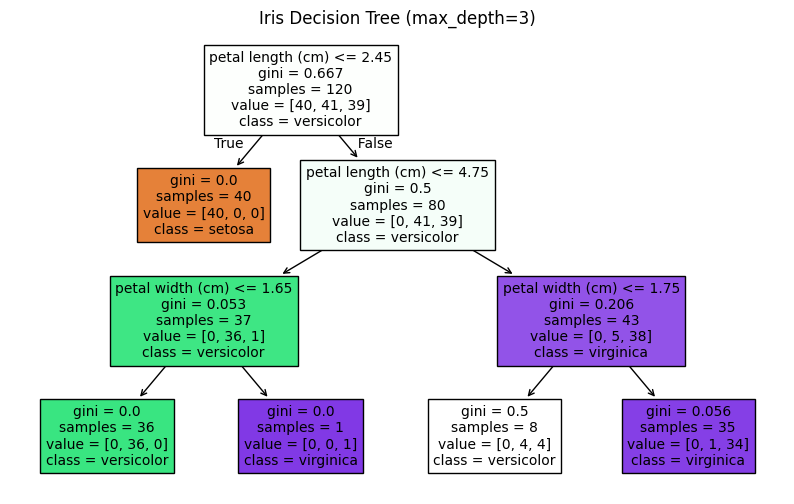

,특성,중요도
0,sepal length (cm),0.000
1,sepal width (cm),0.000
2,petal length (cm),0.935
3,petal width (cm),0.065


In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 문제 2에서 훈련 세트로 학습한 tree를 그대로 시각화
plt.figure(figsize=(10, 6))
plot_tree(tree, filled=True, feature_names=iris.feature_names,
          class_names=iris.target_names)
plt.title('Iris Decision Tree (max_depth=3)')
plt.show()

# 네 특성의 중요도를 데이터프레임으로 정리
df_importance = pd.DataFrame({
    '특성': iris.feature_names,
    '중요도': tree.feature_importances_
})
df_importance.round(3)

---

## 4. 📝 AI 결과 3대 검증 일지

> **💡 [작성 예시]**
> - **1. AI가 한 일:** `train_test_split` 및 `KNeighborsClassifier`/`DecisionTreeClassifier` 분류 코드를 질의하여 작성함
> - **2. 내가 확인한 근거:** 테스트 데이터셋에서 두 모델의 정확도를 직접 비교해 확인함
> - **3. 수정한 점:** 동점 발생 방지를 위해 이웃 수 K를 짝수가 아닌 3(홀수)으로, 트리는 과적합 방지를 위해 max_depth=3으로 고정 적용함

* **1. AI가 한 일 (프롬프트/코드):** feature_importances_ 등 수업 자료 안 코드만 사용하게 설정함
* **2. 내가 확인한 근거 (수작업 대조):** 새 과일 (240, 11)과 가까운 세 점 (230, 11), (250, 14), (220, 12)는 모두 사과이므로 예측값 사과와 일치
* **3. 수정한 점 (개선사항):** 없음